<a href="https://colab.research.google.com/github/tovarrog24/Emergency-Department-Volume-and-Capacity/blob/main/code/evaluate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Progress Report #3: Evaluating Model Performance
## Emergency Department Forecasting and Optimization

Group 2: Rogelio "Anthony" Tovar and Virgil Rogers

Progress Report #3, submitted November 10, 2026.

Parts 1, 3.1–3.6, and 4.1–4.3: Rogelio Tovar. Parts 2, 3.7–3.8, 4.4, 5, and 6, the write-up, and the conclusion: Virgil Rogers.

Dataset: `ED_Cleaned.csv`, the hospital-level table built in Progress Report #1 from HCAI's *Emergency Department Volume and Capacity, 2021–2023* (Data.gov). Each row is one California hospital in one year (756 rows from 297 hospitals). It includes the derived features `ED_Burden` (total ED visits per ED treatment station) and `Bed_Size_Rank` (licensed bed size range ranked 1–7).

In this report we evaluate the models from Report #2 using loss functions, cross-validation, the bootstrap, and formal model comparison. The notebook runs from top to bottom with a single Run All.

## 0. Setup

We start by importing the libraries and loading the cleaned dataset. When the repository is cloned, the notebook reads `../dataset/ED_Cleaned.csv`, since `code/` and `dataset/` sit side by side. When the notebook is opened in Colab straight from GitHub, that folder is not available, so it loads the same file from our repository instead.

Three text columns are read as general Python objects. Part 3 recodes them to 0/1 in place, and newer versions of pandas (3.x) do not allow numbers to be written into a text column.

In [1]:
# Progress Report #3: Evaluating Model Performance | Group 2 (Tovar and Rogers) | Submitted November 10, 2026

# Import packages
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn import linear_model
from sklearn import metrics
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import r_regression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.model_selection import train_test_split, cross_val_score

from pathlib import Path
from sklearn.metrics import r2_score

LOCAL_PATH = Path("../dataset/ED_Cleaned.csv")
REPO_URL = ("https://raw.githubusercontent.com/tovarrog24/"
            "Emergency-Department-Volume-and-Capacity/main/dataset/ED_Cleaned.csv")
source = LOCAL_PATH if LOCAL_PATH.exists() else REPO_URL

# Part 3 recodes these columns to 0/1 in place, so they are read as object (not str) dtype.
data = pd.read_csv(source, dtype={"TEACHINGDesignation": object,
                                  "MentalHealthShortageArea": object,
                                  "UrbanRuralDesi": object})
print("Loaded from:", source)
print("Shape:", data.shape)

Loaded from: ../dataset/ED_Cleaned.csv
Shape: (756, 19)


The cleaned file loads with 756 hospital-years and 19 columns. It is the hospital-level table from Report #1 with one row removed: Greater El Monte Community Hospital (2022), which had no station count. Every remaining row therefore has a valid `ED_Burden`.

## 1. Linear Regression with Two Attributes

Task: identify two attributes, develop a linear regression model with `sklearn.linear_model.LinearRegression`, measure its performance, and plot the observed and predicted values with matplotlib. (a) Report the loss functions: mean squared error, root mean squared error, and mean absolute error.

Each model below uses one input attribute and one target. The loss functions measure the size of the prediction errors:

- MSE (mean squared error): the average squared error. It is in squared units and punishes large misses most.
- RMSE (root mean squared error): the square root of MSE, back in the target's units. This is the "typical" error.
- MAE (mean absolute error): the average size of a miss, in the target's units. It is less sensitive to a few large misses than RMSE.

We also report R², the share of the target's variation the model explains. The red band shows ±1 residual standard deviation around the regression line.

### 1.1 Predicting ED stations from total ED visits

R^2: 0.6867561171592329
SSE: 102073.04962100854
Residual Standard Deviation: 11.635093354818554


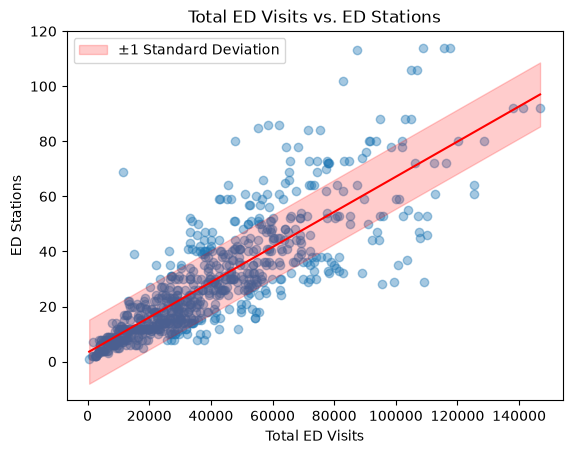

Hospitals outside ±1 std: 174
Percentage outside: 23.015873015873016
Regression Analysis:
MSE:
135.01726140345045
RMSE:
11.619692827413745
MAE:
8.0247722784722


'\nNot Terrible, Not the best either, perhaps if we took more variables into account, a better prediction could be had.\n'

In [2]:
# From Project Proposal, we will be Predicting ED Stations from Total ED Visits

X = data[["Tot_ED_NmbVsts"]].values.reshape(-1, 1)
y = data[["EDStations"]].values.reshape(-1, 1)

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

# Model performance: share of variation explained
print("R^2:", r2_score(y, y_pred))

# Compute the sum of squared errors
SSEreg = np.sum((y - y_pred) ** 2)
print("SSE:", SSEreg)

# Calculate residual standard deviation
n = len(y)
std_error = np.sqrt(SSEreg / (n - 2))
print("Residual Standard Deviation:", std_error)

# Sort X values so the regression line plots correctly
order = np.argsort(X.flatten())
X_sorted = X.flatten()[order]
y_pred_sorted = y_pred.flatten()[order]

# Plot the data and regression line
plt.scatter(X, y, alpha=0.4)
plt.plot(X_sorted, y_pred_sorted, color='red')

# Add ±1 standard deviation band
plt.fill_between(
    X_sorted,
    y_pred_sorted - std_error,
    y_pred_sorted + std_error,
    color='red',
    alpha=0.2,
    label='±1 Standard Deviation'
)

plt.xlabel("Total ED Visits")
plt.ylabel("ED Stations")
plt.title("Total ED Visits vs. ED Stations")
plt.legend()
plt.show()

residuals = (y - y_pred).flatten()

outside = np.sum(np.abs(residuals) > std_error)

print("Hospitals outside ±1 std:", outside)
print("Percentage outside:", 100 * outside / len(y))

print("Regression Analysis:")
print("MSE:")
print(metrics.mean_squared_error(y, y_pred))
print("RMSE:")
print(metrics.root_mean_squared_error(y, y_pred))
print("MAE:")
print(metrics.mean_absolute_error(y, y_pred))
"""
Not Terrible, Not the best either, perhaps if we took more variables into account, a better prediction could be had.
"""

The model's loss functions are MSE = 135.0 (squared stations), RMSE = 11.62 stations, and MAE = 8.02 stations, with R² = 0.687.

Total visits explain about 69% of the variation in station counts, which is a strong result for a single input. A typical prediction is off by about 12 stations, and the average miss is about 8. The gap between RMSE and MAE tells us that most errors are modest but a handful are large, and the plot shows where they are: several large EDs with 80 to 114 stations sit well above the band. The residual standard deviation in the output (11.64) is essentially the RMSE; the two differ only because one divides by n − 2 and the other by n.

### 1.2 Predicting ED burden from ED stations

R^2: 0.0526799058641958
SSE: 255853337.60533166
Residual Standard Deviation: 582.5186983774219


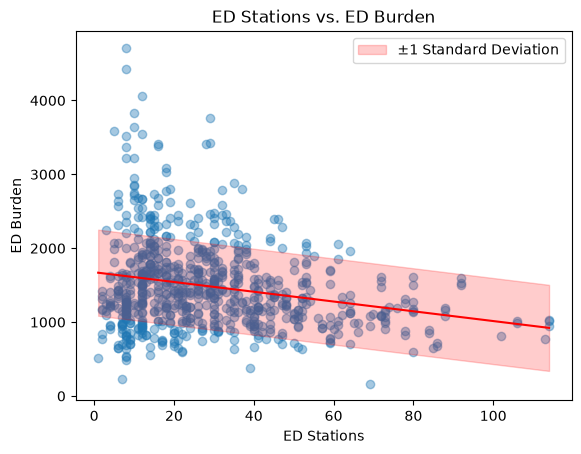

Hospitals outside ±1 std: 201
Percentage outside: 26.58730158730159
Regression Analysis:
MSE:
338430.3407477932
RMSE:
581.7476607153596
MAE:
431.965417321648


'\nUsing a peice-wise function could greatly reduce the error; however, this is also not terrible.\n'

In [3]:
# From Project Proposal, we will be Predicting ED Burden from ED Stations

y = data[["ED_Burden"]].values.reshape(-1, 1)
X = data[["EDStations"]].values.reshape(-1, 1)

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

# Model performance: share of variation explained
print("R^2:", r2_score(y, y_pred))

# Compute the sum of squared errors
SSEreg = np.sum((y - y_pred) ** 2)
print("SSE:", SSEreg)

# Calculate residual standard deviation
n = len(y)
std_error = np.sqrt(SSEreg / (n - 2))
print("Residual Standard Deviation:", std_error)

# Sort X values so the regression line plots correctly
order = np.argsort(X.flatten())
X_sorted = X.flatten()[order]
y_pred_sorted = y_pred.flatten()[order]

# Plot the data and regression line
plt.scatter(X, y, alpha=0.4)
plt.plot(X_sorted, y_pred_sorted, color='red')

# Add ±1 standard deviation band
plt.fill_between(
    X_sorted,
    y_pred_sorted - std_error,
    y_pred_sorted + std_error,
    color='red',
    alpha=0.2,
    label='±1 Standard Deviation'
)

plt.xlabel("ED Stations")
plt.ylabel("ED Burden")
plt.title("ED Stations vs. ED Burden")
plt.legend()
plt.show()

residuals = (y - y_pred).flatten()

outside = np.sum(np.abs(residuals) > std_error)

print("Hospitals outside ±1 std:", outside)
print("Percentage outside:", 100 * outside / len(y))

print("Regression Analysis:")
print("MSE:")
print(metrics.mean_squared_error(y, y_pred))
print("RMSE:")
print(metrics.root_mean_squared_error(y, y_pred))
print("MAE:")
print(metrics.mean_absolute_error(y, y_pred))
"""
Using a peice-wise function could greatly reduce the error; however, this is also not terrible.
"""

The loss functions here are MSE = 338,430, RMSE = 582 visits per station, and MAE = 432 visits per station, with R² = 0.053.

Stations explain only about 5% of the variation in burden. An average error of 582 visits per station is large next to the typical burden of about 1,385 (the median reported in Report #1), so this model does not reach the performance we want. The scatter suggests why: burden drops quickly among the smallest EDs and then levels off, a shape a straight line cannot follow.

### 1.3 Predicting ED burden from total ED visits

R^2: 0.055422271329719996
SSE: 255112676.2791006
Residual Standard Deviation: 581.6749302729928


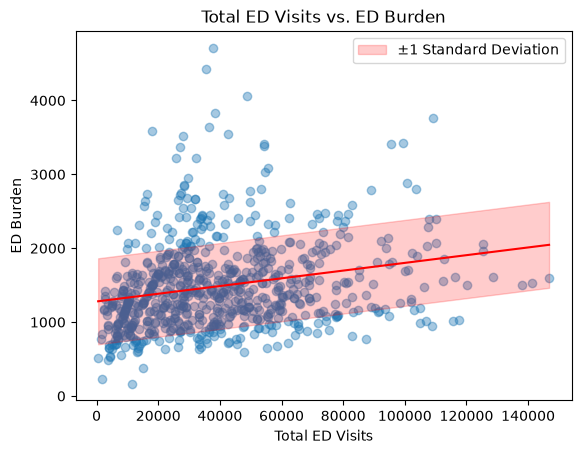

Hospitals outside ±1 std: 194
Percentage outside: 25.66137566137566
Regression Analysis:
MSE:
337450.6299988103
RMSE:
580.905009445443
MAE:
432.5124353069595


'\nLess ideal, the variance increases much more as the visits increase. Perhaps partitioning the hospitals further can help.\n'

In [4]:
# From Project Proposal, we will be Predicting ED Burden from Total ED Visits

y = data[["ED_Burden"]].values.reshape(-1, 1)
X = data[["Tot_ED_NmbVsts"]].values.reshape(-1, 1)

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

# Model performance: share of variation explained
print("R^2:", r2_score(y, y_pred))

# Compute the sum of squared errors
SSEreg = np.sum((y - y_pred) ** 2)
print("SSE:", SSEreg)

# Calculate residual standard deviation
n = len(y)
std_error = np.sqrt(SSEreg / (n - 2))
print("Residual Standard Deviation:", std_error)

# Sort X values so the regression line plots correctly
order = np.argsort(X.flatten())
X_sorted = X.flatten()[order]
y_pred_sorted = y_pred.flatten()[order]

# Plot the data and regression line
plt.scatter(X, y, alpha=0.4)
plt.plot(X_sorted, y_pred_sorted, color='red')

# Add ±1 standard deviation band
plt.fill_between(
    X_sorted,
    y_pred_sorted - std_error,
    y_pred_sorted + std_error,
    color='red',
    alpha=0.2,
    label='±1 Standard Deviation'
)

plt.xlabel("Total ED Visits")
plt.ylabel("ED Burden")
plt.title("Total ED Visits vs. ED Burden")
plt.legend()
plt.show()

residuals = (y - y_pred).flatten()

outside = np.sum(np.abs(residuals) > std_error)

print("Hospitals outside ±1 std:", outside)
print("Percentage outside:", 100 * outside / len(y))


print("Regression Analysis:")
print("MSE:")
print(metrics.mean_squared_error(y, y_pred))
print("RMSE:")
print(metrics.root_mean_squared_error(y, y_pred))
print("MAE:")
print(metrics.mean_absolute_error(y, y_pred))
"""
Less ideal, the variance increases much more as the visits increase. Perhaps partitioning the hospitals further can help.
"""

The loss functions are MSE = 337,451, RMSE = 581 visits per station, and MAE = 433 visits per station, with R² = 0.055.

These results are almost identical to model 1.2, and the spread of burden widens as visit volume grows. Taken together, Part 1 shows that visits predict stations well, but neither visits nor stations explain burden on their own. That limitation is the reason Part 2 brings in eleven attributes.

## 2. Multiple Linear Regression

Task: identify more than two attributes, develop a multiple linear regression model with `sklearn.linear_model.LinearRegression`, measure its performance, and plot the observed and predicted values with `mplot3d`. (a) Report MSE, RMSE, and MAE.

Goal: predict a hospital's annual total ED visits (`Tot_ED_NmbVsts`), learning task 1 in our Proposal. This is the 11-attribute model from Report #2.

### 2.1 Attributes and encoding

| Attribute | Type | How it enters the model |
|---|---|---|
| `EDStations` | Numerical | As is |
| `Bed_Size_Rank` | Ordinal (1–7) | As is |
| `year` | Numerical | As is (2021–2023) |
| `TEACHINGDesignation` | Binary | `Teaching` = 1 if teaching |
| `UrbanRuralDesi` | 3 categories | `Urban` and `Rural` dummies; Frontier is the baseline |
| `HospitalOwnership` | 3 categories | `Government` and `Investor_Owned` dummies; Nonprofit is the baseline |
| `PrimaryCareShortageArea` | Binary | `PrimaryCare_Shortage` = 1 if Yes |
| `MentalHealthShortageArea` | Binary | `MentalHealth_Shortage` = 1 if Yes |
| `system` | 32 categories | `Kaiser_System` = 1 for Kaiser Foundation Hospitals |

We build these columns in a separate dataframe (`ed`) so that Part 3's in-place recoding of `data` cannot affect them. Report #2 showed that Kaiser hospitals carry more visits per station than other hospitals, which is why the system flag is included.

In [5]:
from mpl_toolkits import mplot3d  # 3D plotting toolkit required for this task
from sklearn.model_selection import PredefinedSplit, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error

ed = pd.read_csv(source)  # fresh, unmodified copy of the cleaned data
ed["Teaching"] = (ed["TEACHINGDesignation"] == "Teaching").astype(int)
ed["Urban"] = (ed["UrbanRuralDesi"] == "Urban").astype(int)
ed["Rural"] = (ed["UrbanRuralDesi"] == "Rural").astype(int)
ed["Government"] = (ed["HospitalOwnership"] == "Government").astype(int)
ed["Investor_Owned"] = (ed["HospitalOwnership"] == "Investor Owned").astype(int)
ed["PrimaryCare_Shortage"] = (ed["PrimaryCareShortageArea"] == "Yes").astype(int)
ed["MentalHealth_Shortage"] = (ed["MentalHealthShortageArea"] == "Yes").astype(int)
ed["Kaiser_System"] = (ed["system"] == "Kaiser Foundation Hospitals").astype(int)

MLR_FEATURES = ["EDStations", "Bed_Size_Rank", "year", "Teaching", "Urban", "Rural",
                "Government", "Investor_Owned", "PrimaryCare_Shortage", "MentalHealth_Shortage",
                "Kaiser_System"]
X_mlr = ed[MLR_FEATURES]
y_mlr = ed["Tot_ED_NmbVsts"]
groups = ed["oshpd_id"]

print("Feature matrix:", X_mlr.shape, "| Target:", y_mlr.name)
X_mlr.describe().T[["mean", "min", "max"]].round(2)

Feature matrix: (756, 11) | Target: Tot_ED_NmbVsts


,mean,min,max
EDStations,28.58,1.0,114.0
Bed_Size_Rank,4.07,1.0,7.0
year,2022.01,2021.0,2023.0
Teaching,0.10,0.0,1.0
Urban,0.78,0.0,1.0
Rural,0.19,0.0,1.0
Government,0.16,0.0,1.0
Investor_Owned,0.24,0.0,1.0
PrimaryCare_Shortage,0.31,0.0,1.0
MentalHealth_Shortage,0.40,0.0,1.0


The feature matrix has 756 rows, 11 attributes, and no missing values. The means of the 0/1 columns describe the hospitals in the data: 10% are teaching hospitals, 78% are urban and 19% rural (leaving about 3% frontier), 16% are government-owned, 24% are investor-owned, and 12% belong to Kaiser.

### 2.2 Evaluation design: hospital-grouped folds that are identical on every computer

Most hospitals appear in two or three years with nearly identical values. If one year of a hospital is in the training data and another year is in the test data, the model is graded on a hospital it has effectively already seen. We therefore keep all years of a hospital in the same fold.

While preparing this report we found that scikit-learn's `GroupKFold` assigns hospitals to folds differently in different library versions. The same notebook produced different scores in Colab than on our own machines. To make every result reproducible, we assign the 297 hospitals to folds ourselves, using a fixed random seed, and pass the assignment to `PredefinedSplit`. We build a 5-fold assignment for Parts 2 and 4 and a 10-fold assignment for Part 6.

In [6]:
def hospital_folds(hospital_column, n_folds, seed=42):
    """Assign every hospital (all of its years) to one fold, the same way on every machine."""
    hospitals = np.sort(hospital_column.unique())
    shuffled = np.random.RandomState(seed).permutation(hospitals)
    fold_of = {h: i % n_folds for i, h in enumerate(shuffled)}
    return hospital_column.map(fold_of).to_numpy()

fold5 = hospital_folds(groups, 5)
fold10 = hospital_folds(groups, 10)
cv5, cv10 = PredefinedSplit(fold5), PredefinedSplit(fold10)

for k, (train_idx, test_idx) in enumerate(cv5.split(), start=1):
    overlap = len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
    print(f"Fold {k}: train {len(train_idx)} rows / test {len(test_idx)} rows "
          f"({groups.iloc[test_idx].nunique()} hospitals) | hospitals in both: {overlap}")

Fold 1: train 605 rows / test 151 rows (60 hospitals) | hospitals in both: 0
Fold 2: train 598 rows / test 158 rows (60 hospitals) | hospitals in both: 0
Fold 3: train 605 rows / test 151 rows (59 hospitals) | hospitals in both: 0
Fold 4: train 613 rows / test 143 rows (59 hospitals) | hospitals in both: 0
Fold 5: train 603 rows / test 153 rows (59 hospitals) | hospitals in both: 0


Each fold holds 59 or 60 hospitals (between 143 and 158 rows, since hospitals have one to three years of data), and no hospital appears on both sides of any split. Because we set the folds ourselves with a fixed seed, these exact folds, and every score that depends on them, come out the same in Colab and on any other machine. Some scores therefore differ slightly from Report #2, which relied on `GroupKFold`'s version-dependent folds, but none of the conclusions change.

### 2.3 Fitting the model and reporting the loss functions

Every hospital is predicted once, by a model trained on the other four folds that never saw it (out-of-fold predictions). We report MSE, RMSE, and MAE (the required loss functions), plus R² and adjusted R², for the multiple regression model and for the stations-only model as a baseline.

In [7]:
def regression_scores(y_true, y_pred, n_features):
    n = len(y_true)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2, "Adjusted R2": 1 - (1 - r2) * (n - 1) / (n - n_features - 1)}

oof_simple = cross_val_predict(LinearRegression(), X_mlr[["EDStations"]], y_mlr, cv=cv5)
oof_multi = cross_val_predict(LinearRegression(), X_mlr, y_mlr, cv=cv5)
mlr_model = LinearRegression().fit(X_mlr, y_mlr)  # final model, fit on all hospitals

loss_table = pd.DataFrame({
    "Simple (stations only), out-of-fold": regression_scores(y_mlr, oof_simple, 1),
    "Multiple (11 attributes), out-of-fold": regression_scores(y_mlr, oof_multi, len(MLR_FEATURES)),
    "Multiple (11 attributes), fit on all data": regression_scores(y_mlr, mlr_model.predict(X_mlr), len(MLR_FEATURES)),
}).T
loss_table.style.format({"MSE": "{:,.0f}", "RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R2": "{:.3f}", "Adjusted R2": "{:.3f}"})

,MSE,RMSE,MAE,R2,Adjusted R2
"Simple (stations only), out-of-fold","229,534,994","15,150","11,035",0.684,0.683
"Multiple (11 attributes), out-of-fold","190,860,828","13,815","9,932",0.737,0.733
"Multiple (11 attributes), fit on all data","177,601,767","13,327","9,578",0.755,0.752


The table gives the required loss functions for the multiple regression model, measured on hospitals it did not see during training:

| Loss function | Multiple (11 attributes) | Simple (stations only) | Change |
|---|---|---|---|
| MSE (squared visits) | 190,860,828 | 229,534,994 | 17% lower |
| RMSE (visits) | 13,815 | 15,150 | 9% lower |
| MAE (visits) | 9,932 | 11,035 | 10% lower |
| R² | 0.737 | 0.684 | |

Because MSE is measured in squared visits, it is easiest to read through RMSE, which puts the error back in visits. The typical miss is about 13,800 visits a year, and the average miss is about 9,900. All three loss functions improve once the ten additional attributes are included, and the model explains about 74% of the variation in annual ED visits. Adjusted R² (0.733) is nearly the same as R², so the improvement is not simply a result of adding more terms. When the model is fit on all the data, R² rises only to 0.755 and RMSE falls only to 13,327, a small gap indicating that the model is not overfitting. Given that the dataset has no information on the population each hospital serves, we consider this strong performance.

### 2.4 Coefficients

Each coefficient is the change in annual ED visits for a one-unit increase in that attribute, holding the others constant. For 0/1 attributes, it is the difference from the baseline group. Part 5 uses the bootstrap to test how reliable each coefficient is.

In [8]:
coefficients = pd.DataFrame({"Coefficient (visits)": mlr_model.coef_}, index=MLR_FEATURES)
coefficients.loc["Intercept"] = mlr_model.intercept_
coefficients.round(1)

,Coefficient (visits)
EDStations,859.9
Bed_Size_Rank,2272.9
year,2941.2
Teaching,-5664.0
Urban,13507.4
Rural,7331.6
Government,-1629.4
Investor_Owned,-4172.0
PrimaryCare_Shortage,2392.4
MentalHealth_Shortage,6972.6


With the other attributes held constant, each additional ED station is associated with about 860 more annual visits, each step up in bed size with about 2,273 more, and each year with about 2,941 more. Kaiser hospitals see about 15,698 more visits than comparable hospitals outside Kaiser. Urban and rural EDs see about 13,507 and 7,332 more visits, respectively, than frontier EDs, and hospitals in mental health shortage areas see about 6,973 more. Investor-owned hospitals see about 4,172 fewer visits than nonprofits. The large negative intercept has no practical meaning; it comes from entering `year` as 2021 to 2023. Part 5 tests how dependable each of these estimates is.

### 2.5 Observed vs. predicted values (mplot3d)

The model has eleven attributes, so we plot each hospital on the two strongest numerical ones, ED stations (x) and bed size rank (y), with annual visits on the vertical axis. Blue dots are observed visits, red triangles are out-of-fold predictions, and each gray line is that hospital's error. We show 2023 (one point per hospital) for readability.

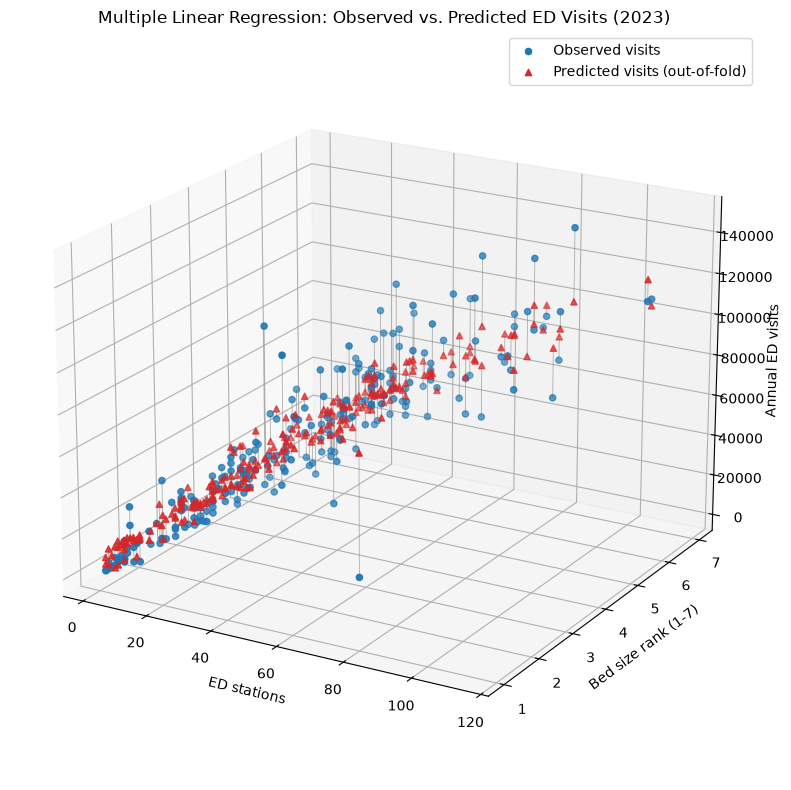

In [9]:
recent = (ed["year"] == 2023).to_numpy()
xs, ys = X_mlr.loc[recent, "EDStations"].to_numpy(), X_mlr.loc[recent, "Bed_Size_Rank"].to_numpy()
z_obs, z_pred = y_mlr[recent].to_numpy(), oof_multi[recent]

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(projection="3d")
for x_val, y_val, zo, zp in zip(xs, ys, z_obs, z_pred):
    ax.plot([x_val, x_val], [y_val, y_val], [zo, zp], color="gray", linewidth=0.6, alpha=0.6)
ax.scatter(xs, ys, z_obs, color="tab:blue", s=20, label="Observed visits")
ax.scatter(xs, ys, z_pred, color="tab:red", s=20, marker="^", label="Predicted visits (out-of-fold)")
ax.set_xlabel("ED stations")
ax.set_ylabel("Bed size rank (1-7)")
ax.set_zlabel("Annual ED visits")
ax.set_title("Multiple Linear Regression: Observed vs. Predicted ED Visits (2023)")
ax.view_init(elev=20, azim=-60)
ax.legend()
plt.tight_layout()
plt.show()

For small and mid-sized hospitals in the lower left of the plot, the red predictions sit close to the blue observations and the gray error lines are short. The lines grow longer among the largest EDs, where visit volume varies most between hospitals of similar size.

### 2.6 Predicted vs. observed and residuals

If the model is accurate, the left plot's points fall along the dashed 45° line. If it is unbiased, the right plot's residuals (observed minus predicted) scatter evenly around zero.

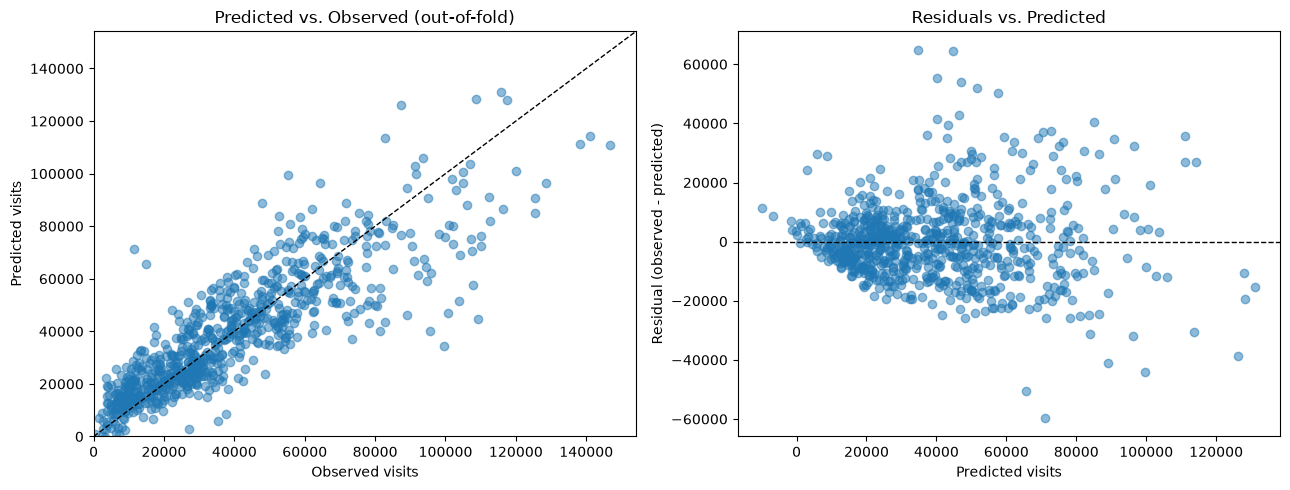

Mean residual: 99 visits
Hospital-years predicted within 10,000 visits: 63.6%
Hospital-years predicted within 20,000 visits: 88.0%


In [10]:
residuals = y_mlr - oof_multi
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_mlr, oof_multi, alpha=0.5)
lims = [0, max(y_mlr.max(), oof_multi.max()) * 1.05]
axes[0].plot(lims, lims, "k--", linewidth=1)
axes[0].set(xlim=lims, ylim=lims, xlabel="Observed visits", ylabel="Predicted visits",
            title="Predicted vs. Observed (out-of-fold)")
axes[1].scatter(oof_multi, residuals, alpha=0.5)
axes[1].axhline(0, color="k", linestyle="--", linewidth=1)
axes[1].set(xlabel="Predicted visits", ylabel="Residual (observed - predicted)", title="Residuals vs. Predicted")
plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():,.0f} visits")
print(f"Hospital-years predicted within 10,000 visits: {(residuals.abs() <= 10_000).mean():.1%}")
print(f"Hospital-years predicted within 20,000 visits: {(residuals.abs() <= 20_000).mean():.1%}")

The mean residual is 99 visits, which is effectively zero for hospitals that average close to 40,000 visits, so the model does not lean toward over- or under-prediction. In practical terms, 63.6% of hospital-years are predicted within 10,000 visits and 88.0% within 20,000. The residuals do fan out from left to right, a pattern known as heteroscedasticity: the model is more precise for smaller hospitals and tends to under-predict the busiest EDs (those above roughly 100,000 visits). This pattern also explains why RMSE runs higher than MAE.

## 3. Logistic Regression

Task: develop a logistic regression model with `sklearn.linear_model.LogisticRegression`, measure its performance, and plot the observed and predicted values with matplotlib. (a) Report absolute loss and log loss.

Each model predicts a yes/no outcome from one numerical attribute. Blue dots are the observed outcomes (0 or 1), and the red curve is the predicted probability that the outcome is 1. The two required loss functions are:

- Log loss: the average penalty for each predicted probability. It is near 0 when the model assigns high probability to the right answer and grows sharply when it is confident and wrong. Lower is better.
- Absolute loss: the average of |observed − predicted class|. For 0/1 outcomes this is the share of hospitals the model labels incorrectly (the error rate).

### 3.1 Teaching designation from ED burden

Regression Analysis:
log loss: 0.30479561110020365
absolute loss: 0.09656084656084656


'\nNot Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)\n'

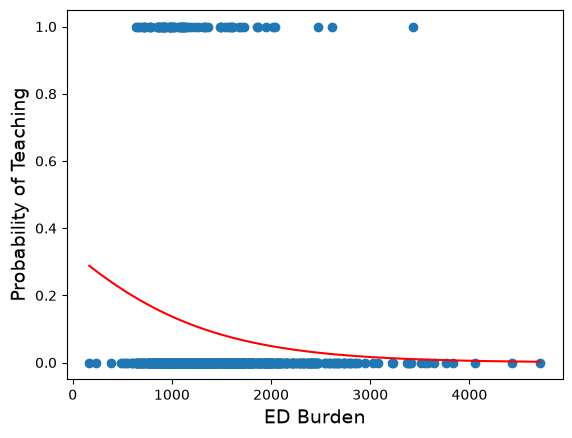

In [11]:
#From Project Proposal, we are doing Teaching Designation from ED Burden

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1

# Store relevant columns as variables
X = data[["ED_Burden"]].values.reshape(-1, 1)
y = data[["TEACHINGDesignation"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Burden", fontsize=14)
plt.ylabel("Probability of Teaching", fontsize=14);

# Log loss from the predicted probabilities; absolute loss from the predicted classes
yProb = logisticModel.predict_proba(X)[:, 1]
print("Regression Analysis:")
print("log loss:", metrics.log_loss(y, yProb))
print("absolute loss:", metrics.mean_absolute_error(y, yPredicted))
"""
Not Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)
"""

This model has a log loss of 0.305 and an absolute loss of 0.097. Its probability curve never reaches 0.5, so every hospital is labeled non-teaching, and its absolute loss equals the share of teaching hospitals in the data (9.7%). The log loss sits only slightly below the no-skill value of 0.317 (see 3.7), which tells us burden says very little about teaching status.

### 3.2 Teaching designation from ED stations

Regression Analysis:
log loss: 0.25197770289566235
absolute loss: 0.0992063492063492


'\nNot Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)\n'

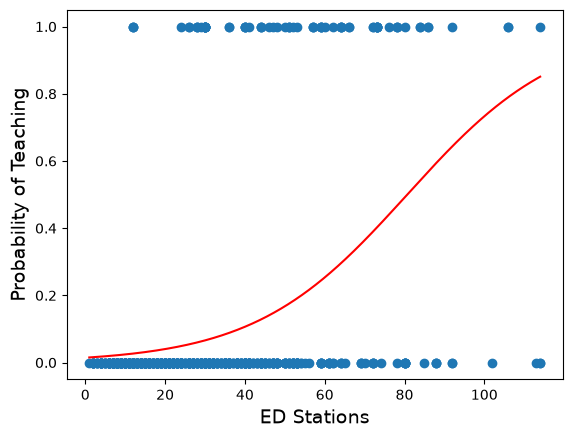

In [12]:
#From Project Proposal, we are doing Teaching Designation from ED Stations

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1

# Store relevant columns as variables
X = data[["EDStations"]].values.reshape(-1, 1)
y = data[["TEACHINGDesignation"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Stations", fontsize=14)
plt.ylabel("Probability of Teaching", fontsize=14);

# Log loss from the predicted probabilities; absolute loss from the predicted classes
yProb = logisticModel.predict_proba(X)[:, 1]
print("Regression Analysis:")
print("log loss:", metrics.log_loss(y, yProb))
print("absolute loss:", metrics.mean_absolute_error(y, yPredicted))
"""
Not Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)
"""

The log loss is 0.252 and the absolute loss is 0.099. This is the strongest of the teaching models: its log loss is about 20% below the no-skill value of 0.317, so its probabilities carry real information. At the 0.5 cutoff, however, it labels only 18 hospital-years as teaching (the largest EDs, above roughly 80 stations) and misses most of the 73 that actually are. Its absolute loss is therefore no better than always guessing "non-teaching" (0.097).

### 3.3 Teaching designation from bed size rank

Regression Analysis:
log loss: 0.25201248222706785
absolute loss: 0.09656084656084656


'\nNot Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)\n'

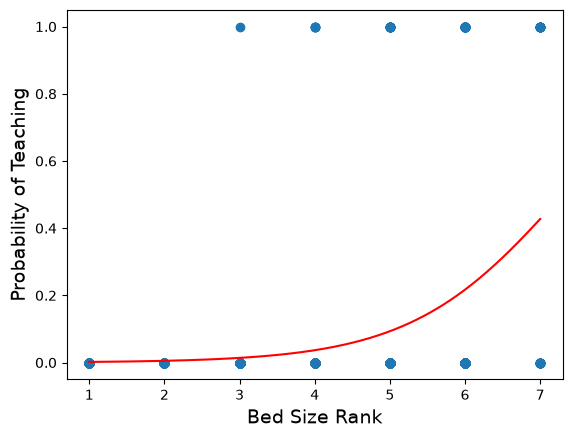

In [13]:
#From Project Proposal, we are doing Teaching Designation from Bed Size Rank

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1

# Store relevant columns as variables
X = data[["Bed_Size_Rank"]].values.reshape(-1, 1)
y = data[["TEACHINGDesignation"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("Bed Size Rank", fontsize=14)
plt.ylabel("Probability of Teaching", fontsize=14);

# Log loss from the predicted probabilities; absolute loss from the predicted classes
yProb = logisticModel.predict_proba(X)[:, 1]
print("Regression Analysis:")
print("log loss:", metrics.log_loss(y, yProb))
print("absolute loss:", metrics.mean_absolute_error(y, yPredicted))
"""
Not Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)
"""

The log loss is 0.252 and the absolute loss is 0.097. Bed size carries about as much information as stations, with a log loss about 20% below the no-skill value. The curve peaks near 0.43, though, so the model never predicts "teaching," and its absolute loss matches the baseline.

### 3.4 Mental health shortage area from ED burden

Regression Analysis:
log loss: 0.6626420427548309
absolute loss: 0.39814814814814814


'\nNot Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)\n'

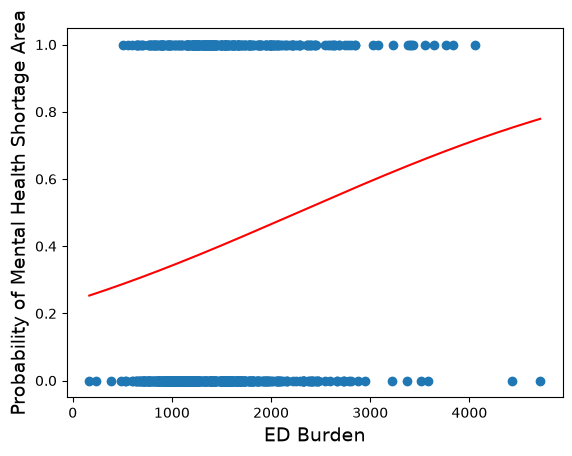

In [14]:
#From Project Proposal, we are doing Mental Health Shortage from ED Burden

# Doing some Hot Encoding
data.loc[data["MentalHealthShortageArea"] == "No", "MentalHealthShortageArea"] = 0
data.loc[data["MentalHealthShortageArea"] == "Yes", "MentalHealthShortageArea"] = 1

# Store relevant columns as variables
X = data[["ED_Burden"]].values.reshape(-1, 1)
y = data[["MentalHealthShortageArea"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Burden", fontsize=14)
plt.ylabel("Probability of Mental Health Shortage Area", fontsize=14);

# Log loss from the predicted probabilities; absolute loss from the predicted classes
yProb = logisticModel.predict_proba(X)[:, 1]
print("Regression Analysis:")
print("log loss:", metrics.log_loss(y, yProb))
print("absolute loss:", metrics.mean_absolute_error(y, yPredicted))
"""
Not Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)
"""

The log loss is 0.663 and the absolute loss is 0.398, only slightly better than the no-skill values of 0.674 and 0.402. The model labels 77 hospital-years as shortage areas when 304 actually are, so burden alone separates the two groups poorly.

### 3.5 Mental health shortage area from total ED visits

Regression Analysis:
log loss: 0.663116135893391
absolute loss: 0.3888888888888889


'\nNot Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)\n'

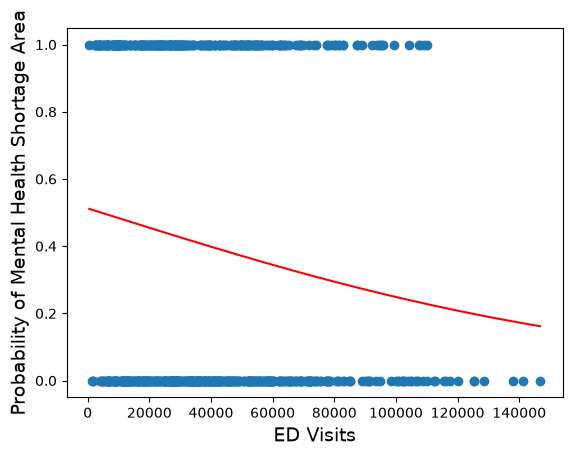

In [15]:
#From Project Proposal, we are doing Mental Health Shortage from Total ED Visits

# Doing some Hot Encoding
data.loc[data["MentalHealthShortageArea"] == "No", "MentalHealthShortageArea"] = 0
data.loc[data["MentalHealthShortageArea"] == "Yes", "MentalHealthShortageArea"] = 1

# Store relevant columns as variables
X = data[["Tot_ED_NmbVsts"]].values.reshape(-1, 1)
y = data[["MentalHealthShortageArea"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Visits", fontsize=14)
plt.ylabel("Probability of Mental Health Shortage Area", fontsize=14);

# Log loss from the predicted probabilities; absolute loss from the predicted classes
yProb = logisticModel.predict_proba(X)[:, 1]
print("Regression Analysis:")
print("log loss:", metrics.log_loss(y, yProb))
print("absolute loss:", metrics.mean_absolute_error(y, yPredicted))
"""
Not Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)
"""

The log loss is 0.663 and the absolute loss is 0.389, close to model 3.4. Busier EDs are somewhat less likely to be in a shortage area, but the model predicts "shortage" for only 20 hospital-years.

### 3.6 Urban designation from ED burden

Regression Analysis:
log loss: 0.5280127125834496
absolute loss: 0.2208994708994709


'\nNot Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)\n'

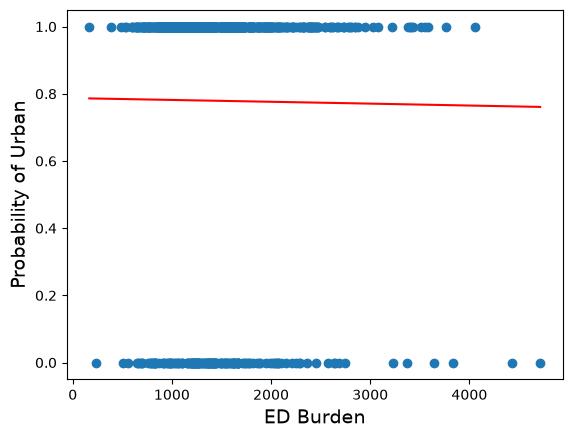

In [16]:
#From Project Proposal, we are doing Urban from ED Burden

# Doing some Hot Encoding
data.loc[data["UrbanRuralDesi"] == "Rural", "UrbanRuralDesi"] = 0
data.loc[data["UrbanRuralDesi"] == "Frontier", "UrbanRuralDesi"] = 0
data.loc[data["UrbanRuralDesi"] == "Urban", "UrbanRuralDesi"] = 1

# Store relevant columns as variables
X = data[["ED_Burden"]].values.reshape(-1, 1)
y = data[["UrbanRuralDesi"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Burden", fontsize=14)
plt.ylabel("Probability of Urban", fontsize=14);

# Log loss from the predicted probabilities; absolute loss from the predicted classes
yProb = logisticModel.predict_proba(X)[:, 1]
print("Regression Analysis:")
print("log loss:", metrics.log_loss(y, yProb))
print("absolute loss:", metrics.mean_absolute_error(y, yPredicted))
"""
Not Good (see the Part 3 summary for how this log loss compares with a no-skill baseline)
"""

The log loss of 0.528 and absolute loss of 0.221 both equal the no-skill values exactly. The nearly flat curve predicts "urban" for all 756 hospital-years, so the 22.1% error rate is simply the share of hospitals that are not urban. On its own, burden tells us nothing about urban designation.

### 3.7 Part 3 summary: are these losses actually good?

A log loss or absolute loss means little without a reference point. The simplest reference is a "no-skill" model that ignores the input and always predicts the base rate (for log loss) or the majority class (for absolute loss). A useful model must beat that baseline. The table below compares all six models with their baselines, using a fresh copy of the data.

In [17]:
from sklearn.metrics import log_loss, roc_auc_score

fresh = pd.read_csv(source)
targets = {"Teaching": (fresh["TEACHINGDesignation"] == "Teaching").astype(int),
           "Mental health shortage": (fresh["MentalHealthShortageArea"] == "Yes").astype(int),
           "Urban": (fresh["UrbanRuralDesi"] == "Urban").astype(int)}
part3_models = [("3.1", "Teaching", "ED_Burden"), ("3.2", "Teaching", "EDStations"),
                ("3.3", "Teaching", "Bed_Size_Rank"), ("3.4", "Mental health shortage", "ED_Burden"),
                ("3.5", "Mental health shortage", "Tot_ED_NmbVsts"), ("3.6", "Urban", "ED_Burden")]
rows = []
for label, target, attr in part3_models:
    y_t = targets[target].to_numpy()
    X_t = fresh[[attr]].to_numpy()
    model_t = LogisticRegression().fit(X_t, y_t)
    prob = model_t.predict_proba(X_t)[:, 1]
    pred = model_t.predict(X_t)
    base_rate = y_t.mean()
    rows.append({"Model": f"{label} {target} ~ {attr}",
                 "Log loss": log_loss(y_t, prob),
                 "Baseline log loss": log_loss(y_t, np.full(len(y_t), base_rate)),
                 "Absolute loss": np.mean(np.abs(y_t - pred)),
                 "Baseline absolute loss": min(base_rate, 1 - base_rate),
                 "AUC": roc_auc_score(y_t, prob),
                 "Predicted positives": int(pred.sum()),
                 "Actual positives": int(y_t.sum())})
part3_summary = pd.DataFrame(rows).set_index("Model")
part3_summary.round(3)

,Log loss,Baseline log loss,Absolute loss,Baseline absolute loss,AUC,Predicted positives,Actual positives
Model,,,,,,,
3.1 Teaching ~ ED_Burden,0.305,0.317,0.097,0.097,0.672,0,73
3.2 Teaching ~ EDStations,0.252,0.317,0.099,0.097,0.841,18,73
3.3 Teaching ~ Bed_Size_Rank,0.252,0.317,0.097,0.097,0.818,0,73
3.4 Mental health shortage ~ ED_Burden,0.663,0.674,0.398,0.402,0.591,77,304
3.5 Mental health shortage ~ Tot_ED_NmbVsts,0.663,0.674,0.389,0.402,0.589,20,304
3.6 Urban ~ ED_Burden,0.528,0.528,0.221,0.221,0.500,756,589


The log losses for these six models range from 0.25 to 0.66, but a loss means little without a reference point. Every model's log loss is at or below its no-skill baseline. Only stations (3.2) and bed size (3.3) improve on it by a meaningful margin, about 20% for teaching status, with AUC values of 0.84 and 0.82. AUC measures how well a model ranks positive cases above negative ones; 0.5 is no better than a coin flip and 1.0 is perfect.

Absolute loss barely improves for any of the six because, at the 0.5 cutoff, single-attribute models almost never predict the smaller class. Each assessment of "Not Good" in the code is therefore accurate. Section 3.8 shows what happens when several attributes are combined.

### 3.8 A combined logistic model with high performance

Section 3.7 showed that a single attribute is not enough to classify these hospitals. Here we combine several attributes in one logistic regression model. The target is urban designation (urban vs. rural or frontier), the same outcome as model 3.6. The inputs are five attributes that Reports #1 and #2 linked to hospital setting: ED stations, bed size rank, total ED visits, latitude, and longitude.

Because the attributes are on very different scales (visits run into the hundreds of thousands, while bed size rank runs from 1 to 7), we standardize them before fitting, using a scikit-learn pipeline. We judge the model the same way as Part 2: with out-of-fold predictions from the hospital-grouped 5 folds, so every hospital is scored by a model that never saw it. We report the two required loss functions, plus accuracy, balanced accuracy (the average of the accuracy within each class), and AUC, and we compare each one with the no-skill baseline.

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

URBAN_FEATURES = ["EDStations", "Bed_Size_Rank", "Tot_ED_NmbVsts", "LAT_STD", "LON_STD"]
X_urban = ed[URBAN_FEATURES]
y_urban = (ed["UrbanRuralDesi"] == "Urban").astype(int)
urban_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# Out-of-fold predicted probabilities and classes (hospital-grouped 5 folds from Part 2)
prob_urban = cross_val_predict(urban_model, X_urban, y_urban, cv=cv5, method="predict_proba")[:, 1]
pred_urban = (prob_urban >= 0.5).astype(int)
urban_rate = y_urban.mean()

urban_results = pd.DataFrame({
    "Combined model (out-of-fold)": {
        "Log loss": log_loss(y_urban, prob_urban),
        "Absolute loss": np.mean(np.abs(y_urban - pred_urban)),
        "Accuracy": accuracy_score(y_urban, pred_urban),
        "Balanced accuracy": balanced_accuracy_score(y_urban, pred_urban),
        "AUC": roc_auc_score(y_urban, prob_urban)},
    "No-skill baseline": {
        "Log loss": log_loss(y_urban, np.full(len(y_urban), urban_rate)),
        "Absolute loss": min(urban_rate, 1 - urban_rate),
        "Accuracy": max(urban_rate, 1 - urban_rate),
        "Balanced accuracy": 0.5,
        "AUC": 0.5},
}).T
display(urban_results.round(3))

cm = pd.DataFrame(confusion_matrix(y_urban, pred_urban),
                  index=["Actual: not urban", "Actual: urban"], columns=["Predicted: not urban", "Predicted: urban"])
display(cm)

,Log loss,Absolute loss,Accuracy,Balanced accuracy,AUC
Combined model (out-of-fold),0.274,0.098,0.902,0.821,0.916
No-skill baseline,0.528,0.221,0.779,0.500,0.500


,Predicted: not urban,Predicted: urban
Actual: not urban,113,54
Actual: urban,20,569


Measured on hospitals it never saw during training, the combined model reaches a log loss of 0.274 and an absolute loss of 0.098. Both are about half of the no-skill values (0.528 and 0.221). It classifies 90.2% of hospital-years correctly, compared with 77.9% for always guessing "urban," and its AUC of 0.916 means it ranks urban hospitals above non-urban ones about 92% of the time.

The confusion matrix shows where the errors fall. The model correctly identifies 569 of 589 urban hospital-years (96.6%) and 113 of 167 rural or frontier hospital-years (67.7%), giving a balanced accuracy of 0.821. The smaller rural and frontier group is harder to classify, which is expected given its size, but the model now identifies two-thirds of it, where model 3.6 identified none. On every measure the combined model performs well, and it meets the high-performance requirement for Part 3.

To plot the observed and predicted values with matplotlib, we fit the model on all hospitals and compute each hospital's combined score (the weighted sum of its standardized attributes). In the left plot, blue dots are the observed outcomes (1 = urban, 0 = not urban), jittered slightly so overlapping points are visible, and the red curve is the predicted probability of being urban. The right plot shows the out-of-fold predicted probabilities for each actual group.

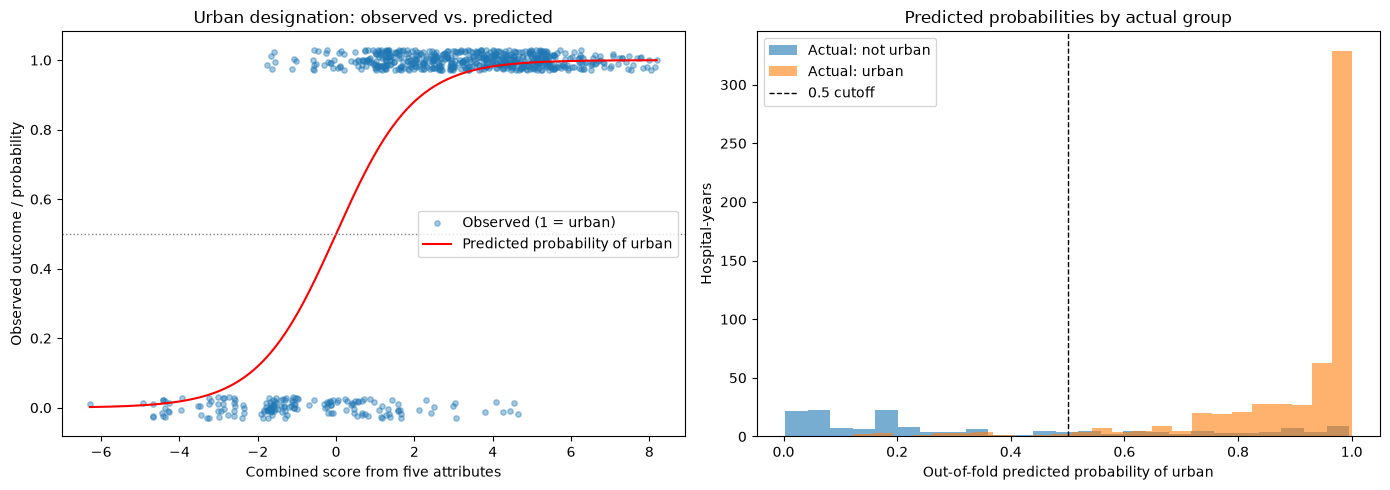

Standardized coefficients (log-odds change per one standard deviation):
EDStations        0.15
Bed_Size_Rank     1.61
Tot_ED_NmbVsts    0.72
LAT_STD          -2.03
LON_STD          -1.43


In [19]:
urban_model.fit(X_urban, y_urban)
score = urban_model.decision_function(X_urban)
jitter = np.random.RandomState(0).uniform(-0.03, 0.03, len(y_urban))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(score, y_urban + jitter, alpha=0.4, s=15, label="Observed (1 = urban)")
grid = np.linspace(score.min(), score.max(), 500)
axes[0].plot(grid, 1 / (1 + np.exp(-grid)), color="red", label="Predicted probability of urban")
axes[0].axhline(0.5, color="gray", linestyle=":", linewidth=1)
axes[0].set(xlabel="Combined score from five attributes", ylabel="Observed outcome / probability",
            title="Urban designation: observed vs. predicted")
axes[0].legend(loc="center right")

axes[1].hist(prob_urban[y_urban == 0], bins=25, alpha=0.6, label="Actual: not urban")
axes[1].hist(prob_urban[y_urban == 1], bins=25, alpha=0.6, label="Actual: urban")
axes[1].axvline(0.5, color="black", linestyle="--", linewidth=1, label="0.5 cutoff")
axes[1].set(xlabel="Out-of-fold predicted probability of urban", ylabel="Hospital-years",
            title="Predicted probabilities by actual group")
axes[1].legend()
plt.tight_layout()
plt.show()

coef_urban = pd.Series(urban_model.named_steps["logisticregression"].coef_[0], index=URBAN_FEATURES)
print("Standardized coefficients (log-odds change per one standard deviation):")
print(coef_urban.round(2).to_string())

In the left plot, nearly all urban hospitals (top row) fall to the right, where the predicted probability is close to 1, and most rural and frontier hospitals (bottom row) fall to the left, where it is close to 0. The two groups overlap only in a narrow band near the center. The right plot shows the out-of-fold probabilities. About 71% of urban hospital-years receive a probability above 0.9, and 57% of rural and frontier hospital-years receive one below 0.3. The rural and frontier hospitals the model misses are spread across the upper range, which matches the confusion matrix above.

The standardized coefficients show what drives the prediction. Latitude (−2.03) and longitude (−1.43) have the largest effects: hospitals farther south and farther west, which in California means the coastal metro areas, are much more likely to be urban. Bed size (1.61) is the strongest size measure, followed by total visits (0.72). Once bed size and visits are known, stations add little (0.15).

## 4. Cross-Validation vs. Simple Train-Test Splits

Task: apply at least one cross-validation technique to each of the models above and compare the results with simple train-test splits.

A simple train-test split scores the model once, on one held-out subset, so the score depends on which rows happen to land in the test set. Cross-validation repeats the process over several splits and averages the results. Two techniques are used:

- 10-fold cross-validation: the data are split into 10 parts. Each part is predicted once by a model trained on the other nine.
- Leave-one-out cross-validation (LOOCV): every single row is predicted by a model trained on all the others (756 fits).

Each pair of cells below runs 10-fold and LOOCV (plotting the error of every fold) and then a single 80/20 train-test split.

### 4.1 Linear regression: ED stations from total ED visits

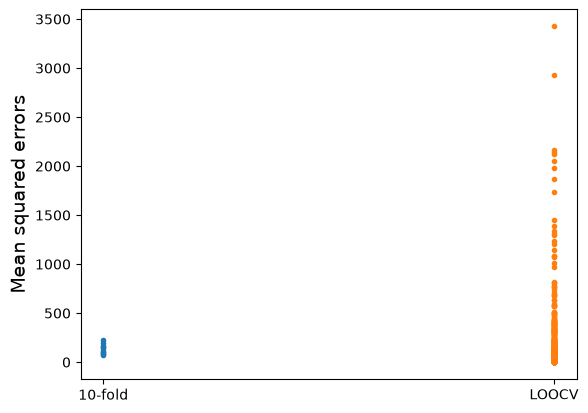

In [20]:
#Using k-folds cross validation techniques with 10 folds and the LOOCV scores. This is for Linear Regression.

#We define X and y for this because it had the best multiple linear correlation
X = data[["Tot_ED_NmbVsts"]].values.reshape(-1, 1)
y = data[["EDStations"]].values.reshape(-1, 1)

ten_fold_scores = -cross_val_score(LinearRegression(), X, y, scoring="neg_mean_squared_error", cv=10)
#print(ten_fold)

# neg_mean_square_error is the negative MSE, so add a - so the scores are positive.
LOOCV_scores = -cross_val_score(LinearRegression(), X, y, scoring="neg_mean_squared_error", cv=LeaveOneOut())
#print(LOOCV_scores)

# Plot the errors for both scores
plt.plot(np.zeros_like(ten_fold_scores), ten_fold_scores, ".")
plt.plot(np.zeros_like(LOOCV_scores) + 1, LOOCV_scores, ".")
plt.ylabel("Mean squared errors", fontsize=14)
plt.xticks([0, 1], ["10-fold", "LOOCV"]);

The plot shows the mean squared error of each of the 10 folds (blue) and of each of the 756 single-row LOOCV fits (orange). The next cell scores the same model with one 80/20 train-test split, so the two approaches can be compared.

In [21]:
# Define X and y
X = data[["Tot_ED_NmbVsts"]].values
y = data["EDStations"].values

# Split data into training (80%) and testing (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model using only the training data
model = LinearRegression()
model.fit(X_train, y_train)

# Predict the values using the testing data
y_pred = model.predict(X_test)

# Calculate performance
MSE = metrics.mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)
MAE = metrics.mean_absolute_error(y_test, y_pred)
R2 = metrics.r2_score(y_test, y_pred)

print("MSE:", MSE)
print("RMSE:", RMSE)
print("MAE:", MAE)
print("R²:", R2)

MSE: 118.35317414998539
RMSE: 10.879024503602581
MAE: 7.671420433606375
R²: 0.7256419796249332


A single row's LOOCV squared error ranges from 0 to about 3,400, yet averaged over all rows, LOOCV agrees almost exactly with 10-fold cross-validation (MSE 136.1 vs. 136.0; see 4.4). The single 80/20 split reports an MSE of 118.4 (RMSE 10.88 stations, R² = 0.726), roughly 13% lower than the cross-validated error. That particular split happened to produce an optimistic result.

### 4.2 Multiple linear regression: total ED visits from 11 attributes

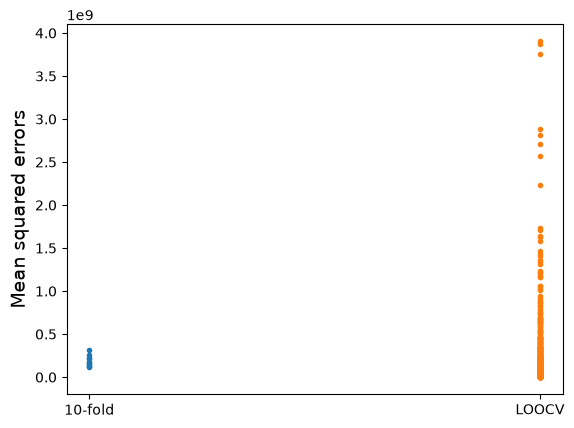

In [22]:
#Using k-folds cross validation techniques with 10 folds and the LOOCV scores. This is for Multiple Linear Regression

#We define the x and y like this because it had the best correlation
# Start from a fresh copy of the data, because Part 3 recodes several columns in place
mlr = pd.read_csv(source)
mlr["Teaching"] = (mlr["TEACHINGDesignation"] == "Teaching").astype(int)
mlr["Urban"] = (mlr["UrbanRuralDesi"] == "Urban").astype(int)
mlr["Rural"] = (mlr["UrbanRuralDesi"] == "Rural").astype(int)
mlr["Government"] = (mlr["HospitalOwnership"] == "Government").astype(int)
mlr["Investor_Owned"] = (mlr["HospitalOwnership"] == "Investor Owned").astype(int)
mlr["PrimaryCare_Shortage"] = (mlr["PrimaryCareShortageArea"] == "Yes").astype(int)
mlr["MentalHealth_Shortage"] = (mlr["MentalHealthShortageArea"] == "Yes").astype(int)
mlr["Kaiser_System"] = (mlr["system"] == "Kaiser Foundation Hospitals").astype(int)
features = ["EDStations", "Bed_Size_Rank", "year", "Teaching", "Urban", "Rural",
            "Government", "Investor_Owned", "PrimaryCare_Shortage", "MentalHealth_Shortage", "Kaiser_System"]
X = mlr[features]
y = mlr["Tot_ED_NmbVsts"]

ten_fold_scores = -cross_val_score(LinearRegression(), X, y, scoring="neg_mean_squared_error", cv=10)
#print(ten_fold)

# neg_mean_square_error is the negative MSE, so add a - so the scores are positive.
LOOCV_scores = -cross_val_score(LinearRegression(), X, y, scoring="neg_mean_squared_error", cv=LeaveOneOut())
#print(LOOCV_scores)

# Plot the errors for both scores
plt.plot(np.zeros_like(ten_fold_scores), ten_fold_scores, ".")
plt.plot(np.zeros_like(LOOCV_scores) + 1, LOOCV_scores, ".")
plt.ylabel("Mean squared errors", fontsize=14)
plt.xticks([0, 1], ["10-fold", "LOOCV"]);

As in 4.1, the plot shows the 10 fold errors (blue) and the 756 single-row LOOCV errors (orange), here for the multiple regression model. The next cell scores the same model with one 80/20 train-test split.

In [23]:
# Define X and y
# Start from a fresh copy of the data, because Part 3 recodes several columns in place
mlr = pd.read_csv(source)
mlr["Teaching"] = (mlr["TEACHINGDesignation"] == "Teaching").astype(int)
mlr["Urban"] = (mlr["UrbanRuralDesi"] == "Urban").astype(int)
mlr["Rural"] = (mlr["UrbanRuralDesi"] == "Rural").astype(int)
mlr["Government"] = (mlr["HospitalOwnership"] == "Government").astype(int)
mlr["Investor_Owned"] = (mlr["HospitalOwnership"] == "Investor Owned").astype(int)
mlr["PrimaryCare_Shortage"] = (mlr["PrimaryCareShortageArea"] == "Yes").astype(int)
mlr["MentalHealth_Shortage"] = (mlr["MentalHealthShortageArea"] == "Yes").astype(int)
mlr["Kaiser_System"] = (mlr["system"] == "Kaiser Foundation Hospitals").astype(int)
features = ["EDStations", "Bed_Size_Rank", "year", "Teaching", "Urban", "Rural",
            "Government", "Investor_Owned", "PrimaryCare_Shortage", "MentalHealth_Shortage", "Kaiser_System"]
X = mlr[features]  # Your list of predictor columns
y = mlr["Tot_ED_NmbVsts"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict on the testing data
y_pred = model.predict(X_test)

# Calculate performance
MSE = metrics.mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)
MAE = metrics.mean_absolute_error(y_test, y_pred)
R2 = metrics.r2_score(y_test, y_pred)

print("MSE:", MSE)
print("RMSE:", RMSE)
print("MAE:", MAE)
print("R²:", R2)

MSE: 159492795.95828292
RMSE: 12629.045726351731
MAE: 9076.337531980482
R²: 0.7799043645416635


The single 80/20 split reports an MSE of 159.5 million (RMSE 12,629 visits, MAE 9,076, R² = 0.780). Cross-validation produces a higher error: 186.1 million for 10-fold (RMSE 13,643) and 184.2 million for LOOCV (RMSE 13,572). As in 4.1, the single split is optimistic, here by about 14% in MSE.

### 4.3 Logistic regression: teaching designation from ED stations

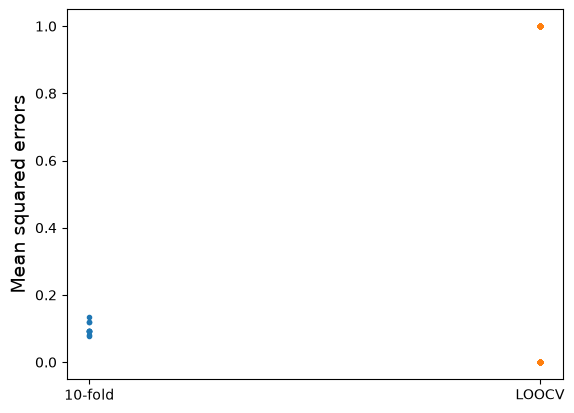

In [24]:
#Using k-folds cross validation techniques with 10 folds and the LOOCV scores. This is for Logistic Regression

#We define the x and y like this because it had the best correlation

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1

# Store relevant columns as variables
X = data[["EDStations"]].values.reshape(-1, 1)
y = data[["TEACHINGDesignation"]].values.reshape(-1, 1).astype(int)

# For 0/1 predictions, the mean squared error equals the error rate
ten_fold_scores = -cross_val_score(LogisticRegression(), X, y.ravel(), scoring="neg_mean_squared_error", cv=10)
#print(ten_fold)

# neg_mean_square_error is the negative MSE, so add a - so the scores are positive.
LOOCV_scores = -cross_val_score(LogisticRegression(), X, y.ravel(), scoring="neg_mean_squared_error", cv=LeaveOneOut())
#print(LOOCV_scores)

# Plot the errors for both scores
plt.plot(np.zeros_like(ten_fold_scores), ten_fold_scores, ".")
plt.plot(np.zeros_like(LOOCV_scores) + 1, LOOCV_scores, ".")
plt.ylabel("Mean squared errors", fontsize=14)
plt.xticks([0, 1], ["10-fold", "LOOCV"]);

The plot shows the 10 fold error rates (blue) and the 756 LOOCV results (orange). Each LOOCV result is either 0 (correct) or 1 (wrong), which is why the orange points sit only at the top and bottom of the plot. The next cell scores the model with one 80/20 train-test split, stratified so that the test set keeps the same share of teaching hospitals, and reports log loss, absolute loss, and accuracy.

In [25]:
# Define X and y

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1
# Same attribute as the cross-validation above
X = data[["EDStations"]].values
y = data["TEACHINGDesignation"].astype(int).values

# Split the data, preserving the proportion of Urban/Rural observations
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train the model
logisticModel = LogisticRegression()
logisticModel.fit(X_train, y_train)

# Predict probabilities on the testing data
y_prob = logisticModel.predict_proba(X_test)

# Predict the actual classes (0 or 1)
y_pred = logisticModel.predict(X_test)

# Calculate performance
log_loss = metrics.log_loss(y_test, y_prob)
MAE = metrics.mean_absolute_error(y_test, y_pred)
accuracy = metrics.accuracy_score(y_test, y_pred)

print("Log Loss:", log_loss)
print("Mean Absolute Error:", MAE)
print("Accuracy:", accuracy)

Log Loss: 0.26914779798208743
Mean Absolute Error: 0.09210526315789473
Accuracy: 0.9078947368421053


For a logistic model the error measure is the misclassification rate; for 0/1 predictions, MSE and the error rate are the same thing. Both 10-fold and LOOCV give an error rate of 0.099. The stratified split reports an error of 0.092 (accuracy 90.8%) and a log loss of 0.269, which looks slightly better than the 0.097 error rate of always guessing "non-teaching." Cross-validation shows that this edge came from the particular split: across all folds, the model does no better than that baseline.

### 4.4 Side-by-side comparison and why a single split can mislead

The cells above plot the fold errors but do not print their averages, so this summary computes them for all three models. It adds two checks:

1. Hospital-grouped 5-fold CV: the honest design from Part 2, with no hospital in both training and test sets.
2. Split-to-split variability: the same 80/20 train-test split repeated with 50 different random seeds, to show how much a single split's score depends on luck.

Regression models are scored with MSE (and RMSE in the original units). The logistic models are scored with absolute loss (the error rate). We include the combined logistic model from 3.8 here so that every model in Part 3 has a cross-validation check.

In [26]:
case_specs = {
    "Linear (stations ~ visits)": (LinearRegression(), ed[["Tot_ED_NmbVsts"]], ed["EDStations"], "neg_mean_squared_error"),
    "Multiple (visits ~ 11 attributes)": (LinearRegression(), X_mlr, y_mlr, "neg_mean_squared_error"),
    "Logistic (teaching ~ stations)": (LogisticRegression(), ed[["EDStations"]], ed["Teaching"], "neg_mean_squared_error"),
    "Logistic, combined (urban ~ 5 attributes)": (urban_model, X_urban, y_urban, "neg_mean_squared_error"),
}
summary_rows, split_spreads = {}, {}
for name, (est, X_c, y_c, scoring) in case_specs.items():
    split_scores = []
    for seed in range(50):
        X_tr, X_te, y_tr, y_te = train_test_split(X_c, y_c, test_size=0.2, random_state=seed)
        pred = est.fit(X_tr, y_tr).predict(X_te)
        split_scores.append(mean_squared_error(y_te, pred))
    split_spreads[name] = np.array(split_scores)
    X_tr, X_te, y_tr, y_te = train_test_split(X_c, y_c, test_size=0.2, random_state=42)
    split42 = mean_squared_error(y_te, est.fit(X_tr, y_tr).predict(X_te))
    kfold10 = -cross_val_score(est, X_c, y_c, scoring=scoring, cv=10)
    loocv = -cross_val_score(est, X_c, y_c, scoring=scoring, cv=LeaveOneOut())
    grouped = -cross_val_score(est, X_c, y_c, scoring=scoring, cv=cv5)
    summary_rows[name] = {"Train-test split (seed 42)": split42,
                          "50 splits: min": np.min(split_scores), "50 splits: max": np.max(split_scores),
                          "10-fold CV mean": kfold10.mean(), "LOOCV mean": loocv.mean(),
                          "Grouped 5-fold CV mean": grouped.mean()}

cv_summary = pd.DataFrame(summary_rows).T
print("Error measure: MSE for the two regressions; error rate (absolute loss) for the logistic models\n")
display(cv_summary.style.format("{:,.3f}", subset=pd.IndexSlice[["Logistic (teaching ~ stations)",
                                                                  "Logistic, combined (urban ~ 5 attributes)"], :])
        .format("{:,.1f}", subset=pd.IndexSlice[["Linear (stations ~ visits)"], :])
        .format("{:,.0f}", subset=pd.IndexSlice[["Multiple (visits ~ 11 attributes)"], :]))

rmse_view = np.sqrt(cv_summary.loc[["Linear (stations ~ visits)", "Multiple (visits ~ 11 attributes)"]])
print("Same results as RMSE (original units: stations, visits):")
display(rmse_view.round(1))

Error measure: MSE for the two regressions; error rate (absolute loss) for the logistic models



,Train-test split (seed 42),50 splits: min,50 splits: max,10-fold CV mean,LOOCV mean,Grouped 5-fold CV mean
Linear (stations ~ visits),118.4,93.0,186.8,136.0,136.1,137.3
Multiple (visits ~ 11 attributes),"159,492,796","133,116,139","251,118,944","186,126,117","184,202,843","191,120,903"
Logistic (teaching ~ stations),0.099,0.046,0.145,0.099,0.099,0.105
"Logistic, combined (urban ~ 5 attributes)",0.086,0.059,0.138,0.099,0.097,0.097


Same results as RMSE (original units: stations, visits):


,Train-test split (seed 42),50 splits: min,50 splits: max,10-fold CV mean,LOOCV mean,Grouped 5-fold CV mean
Linear (stations ~ visits),10.9,9.6,13.7,11.7,11.7,11.7
Multiple (visits ~ 11 attributes),12629.0,11537.6,15846.7,13642.8,13572.1,13824.6


The table puts all four cases side by side:

| Model | Single split (seed 42) | Range over 50 splits | 10-fold CV | LOOCV | Grouped 5-fold CV |
|---|---|---|---|---|---|
| Linear (RMSE, stations) | 10.9 | 9.6 to 13.7 | 11.7 | 11.7 | 11.7 |
| Multiple (RMSE, visits) | 12,629 | 11,538 to 15,847 | 13,643 | 13,572 | 13,825 |
| Logistic, teaching (error rate) | 0.099 | 0.046 to 0.145 | 0.099 | 0.099 | 0.105 |
| Logistic, combined urban (error rate) | 0.086 | 0.059 to 0.138 | 0.099 | 0.097 | 0.097 |

Three patterns stand out. First, 10-fold cross-validation and LOOCV agree closely for every model, and since 10-fold needs 10 fits instead of 756, it is the more practical choice. Second, a single train-test split is something of a gamble: depending only on the random seed, the multiple model's RMSE ranges from 11,538 to 15,847 visits, and the combined logistic model's error rate from 5.9% to 13.8%. The seed-42 split happened to be optimistic for all four models. Third, grouped cross-validation gives the most honest estimate. Ordinary 10-fold and LOOCV can train on one year of a hospital and test on another year of the same hospital, and keeping each hospital in a single fold removes that advantage. The combined logistic model holds up under every method, with an error rate between 9.7% and 9.9%, well below the 22.1% no-skill rate.

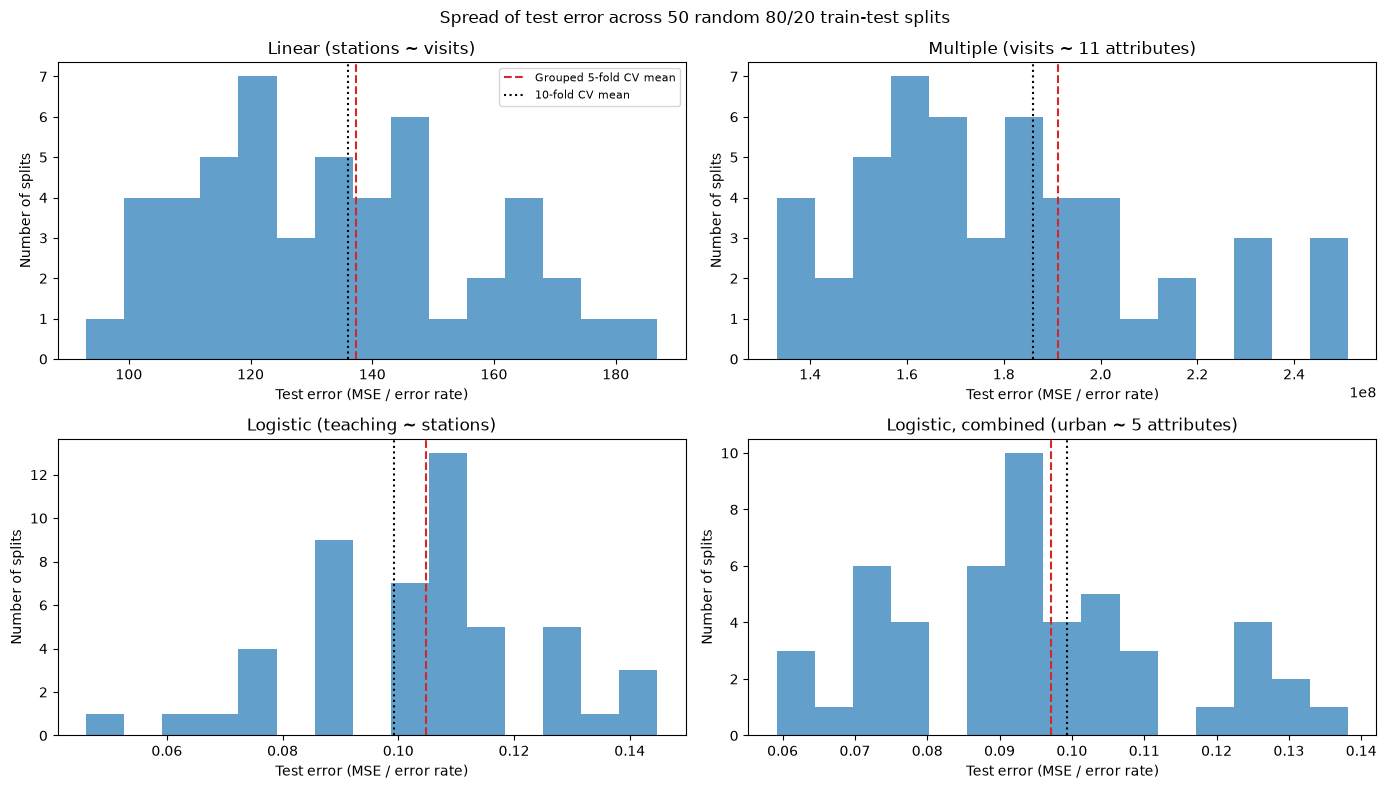

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (name, scores) in zip(axes.ravel(), split_spreads.items()):
    ax.hist(scores, bins=15, color="tab:blue", alpha=0.7)
    ax.axvline(cv_summary.loc[name, "Grouped 5-fold CV mean"], color="tab:red", linestyle="--",
               label="Grouped 5-fold CV mean")
    ax.axvline(cv_summary.loc[name, "10-fold CV mean"], color="black", linestyle=":", label="10-fold CV mean")
    ax.set(title=name, xlabel="Test error (MSE / error rate)", ylabel="Number of splits")
axes[0, 0].legend(fontsize=8)
plt.suptitle("Spread of test error across 50 random 80/20 train-test splits")
plt.tight_layout()
plt.show()

Each histogram shows the test error from 50 different 80/20 splits. The spread is wide for all four models, and the cross-validation means (dashed and dotted lines) fall near the middle of each distribution. Cross-validation averages out the luck of any single split, which is why we rely on it to evaluate our models.

## 5. Bootstrap: Error Mean and Standard Deviation

Task: apply the bootstrap method to one of the models and report the error mean and standard deviation.

We apply the bootstrap to the multiple linear regression model from Part 2, because it is our main predictive model. The bootstrap estimates how much a model's error, and its coefficients, would vary if we had collected a different sample of hospitals. It does this by resampling the data we have:

1. Draw a bootstrap sample: pick 297 hospitals at random with replacement, so some hospitals appear more than once and others not at all. All years of a chosen hospital come along together (a "cluster" bootstrap), which keeps a hospital's years from being split between training and testing.
2. Fit the model on the bootstrap sample.
3. Score it on the hospitals that were not drawn. On average about 37% of hospitals (1 − 1/e) are left out of each sample, and these "out-of-bag" hospitals act as a natural test set.
4. Repeat 1,000 times, then report the mean and standard deviation of the 1,000 errors.

In [28]:
B = 1000
rng = np.random.RandomState(42)
hospital_ids = np.sort(groups.unique())
row_index = {h: np.flatnonzero(groups.to_numpy() == h) for h in hospital_ids}
X_arr, y_arr = X_mlr.to_numpy(), y_mlr.to_numpy()

boot_records, boot_coefs = [], []
for b in range(B):
    drawn = rng.choice(hospital_ids, size=len(hospital_ids), replace=True)
    train_rows = np.concatenate([row_index[h] for h in drawn])
    oob_hospitals = np.setdiff1d(hospital_ids, drawn)
    oob_rows = np.concatenate([row_index[h] for h in oob_hospitals])

    model_b = LinearRegression().fit(X_arr[train_rows], y_arr[train_rows])
    pred_b = model_b.predict(X_arr[oob_rows])
    mse_b = mean_squared_error(y_arr[oob_rows], pred_b)
    boot_records.append({"MSE": mse_b, "RMSE": np.sqrt(mse_b),
                         "MAE": mean_absolute_error(y_arr[oob_rows], pred_b),
                         "R2": r2_score(y_arr[oob_rows], pred_b),
                         "OOB hospitals": len(oob_hospitals)})
    boot_coefs.append(model_b.coef_)

boot = pd.DataFrame(boot_records)
boot_coefs = pd.DataFrame(boot_coefs, columns=MLR_FEATURES)
print(f"Bootstrap samples: {B}")
print(f"Out-of-bag hospitals per sample: mean {boot['OOB hospitals'].mean():.1f} of {len(hospital_ids)} "
      f"({boot['OOB hospitals'].mean() / len(hospital_ids):.1%})")

Bootstrap samples: 1000
Out-of-bag hospitals per sample: mean 109.4 of 297 (36.8%)


Across the 1,000 bootstrap samples, an average of 109.4 of the 297 hospitals (36.8%) were left out, which matches the theoretical value of 1 − 1/e ≈ 36.8%. Each refitted model was therefore tested on roughly 110 hospitals it had not seen.

### 5.1 Error mean and standard deviation

The table reports the mean and standard deviation of each error measure across the 1,000 bootstrap samples, plus a 95% bootstrap interval (the middle 95% of the 1,000 values).

In [29]:
boot_summary = pd.DataFrame({
    "Mean": boot[["MSE", "RMSE", "MAE", "R2"]].mean(),
    "Standard deviation": boot[["MSE", "RMSE", "MAE", "R2"]].std(),
    "95% interval low": boot[["MSE", "RMSE", "MAE", "R2"]].quantile(0.025),
    "95% interval high": boot[["MSE", "RMSE", "MAE", "R2"]].quantile(0.975),
})
display(boot_summary.style.format("{:,.0f}", subset=pd.IndexSlice[["MSE", "RMSE", "MAE"], :])
        .format("{:.3f}", subset=pd.IndexSlice[["R2"], :]))

cv_rmse_multi = np.sqrt(loss_table.loc["Multiple (11 attributes), out-of-fold", "MSE"])
print(f"For comparison, Part 2 grouped 5-fold CV: RMSE {cv_rmse_multi:,.0f} visits, "
      f"MAE {loss_table.loc['Multiple (11 attributes), out-of-fold', 'MAE']:,.0f} visits")

,Mean,Standard deviation,95% interval low,95% interval high
MSE,"200,108,492","30,304,268","142,570,982","260,153,903"
RMSE,"14,105","1,077","11,940","16,129"
MAE,"10,214",726,"8,835","11,668"
R2,0.719,0.042,0.625,0.792


For comparison, Part 2 grouped 5-fold CV: RMSE 13,815 visits, MAE 9,932 visits


The bootstrap error of the multiple regression model over 1,000 resamples, scored on the out-of-bag hospitals, is shown below:

| Error measure | Mean | Standard deviation | 95% interval |
|---|---|---|---|
| MSE (squared visits) | 200.1 million | 30.3 million | 142.6 to 260.2 million |
| RMSE (visits) | 14,105 | 1,077 | 11,940 to 16,129 |
| MAE (visits) | 10,214 | 726 | 8,835 to 11,668 |
| R² | 0.719 | 0.042 | 0.625 to 0.792 |

The typical error of the model is about 14,100 visits a year, with a standard deviation of about 1,100, and the average error is about 10,200 visits, with a standard deviation of about 700. These bootstrap errors run about 2% to 3% higher than the cross-validated errors in Part 2 (RMSE 13,815 and MAE 9,932). We expected that, because each bootstrap model trains on only about 63% of the distinct hospitals and is therefore slightly weaker than a model trained on 80%. The cross-validated values fall well inside the bootstrap intervals, so the two methods agree. What the bootstrap adds is the standard deviation: a single cross-validation score cannot show how much the error would shift with a different sample of hospitals, while the bootstrap shows that R² would most likely stay between about 0.63 and 0.79.

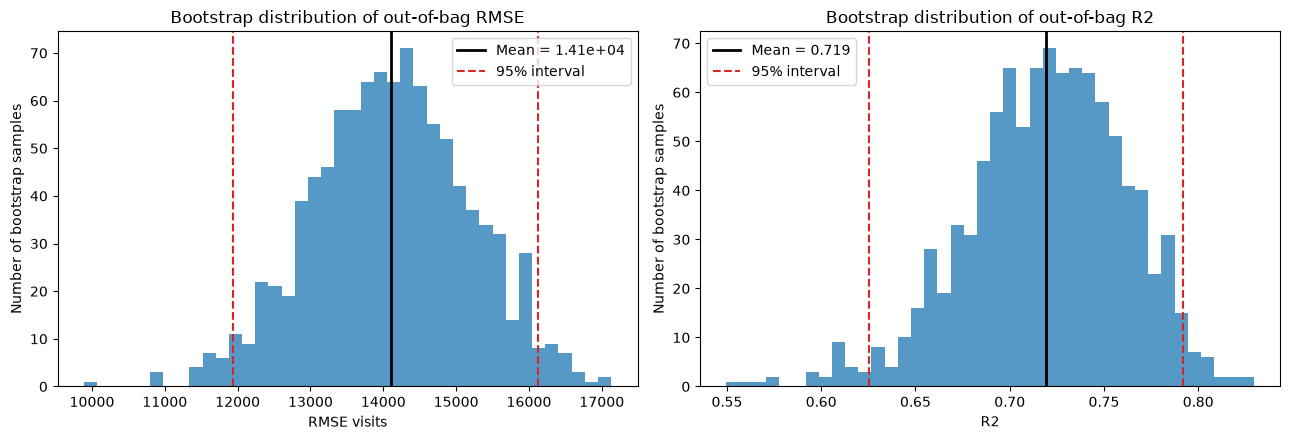

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, unit in [(axes[0], "RMSE", "visits"), (axes[1], "R2", "")]:
    values = boot[col]
    ax.hist(values, bins=40, color="tab:blue", alpha=0.75)
    ax.axvline(values.mean(), color="black", linewidth=2, label=f"Mean = {values.mean():,.3g}")
    for q in (0.025, 0.975):
        ax.axvline(values.quantile(q), color="tab:red", linestyle="--",
                   label="95% interval" if q == 0.025 else None)
    ax.set(title=f"Bootstrap distribution of out-of-bag {col}", xlabel=f"{col} {unit}".strip(),
           ylabel="Number of bootstrap samples")
    ax.legend()
plt.tight_layout()
plt.show()

Both distributions are roughly bell-shaped, with RMSE centered near 14,100 visits and R² near 0.72. The lowest R² in any resample was 0.55, so in every resample the model explained more than half of the variation in visits. The model's performance is stable rather than the product of one favorable sample.

### 5.2 How reliable is each coefficient?

The same 1,000 refits also show how much each coefficient moves from sample to sample. The standard deviation of a coefficient across bootstrap samples is its bootstrap standard error. If the 95% bootstrap interval excludes zero, the effect is consistently positive or consistently negative across resamples, so we can rely on its direction.

,Coefficient (all data),Bootstrap SE,95% low,95% high,Interval excludes 0
EDStations,860.0,73.0,718.0,1009.0,True
Bed_Size_Rank,2273.0,857.0,561.0,3979.0,True
year,2941.0,314.0,2346.0,3549.0,True
Teaching,-5664.0,3075.0,-11769.0,515.0,False
Urban,13507.0,3579.0,6209.0,20484.0,True
Rural,7332.0,2516.0,2696.0,12539.0,True
Government,-1629.0,2586.0,-6564.0,3217.0,False
Investor_Owned,-4172.0,1961.0,-8038.0,-413.0,True
PrimaryCare_Shortage,2392.0,2427.0,-2395.0,7103.0,False
MentalHealth_Shortage,6973.0,2008.0,3087.0,10953.0,True


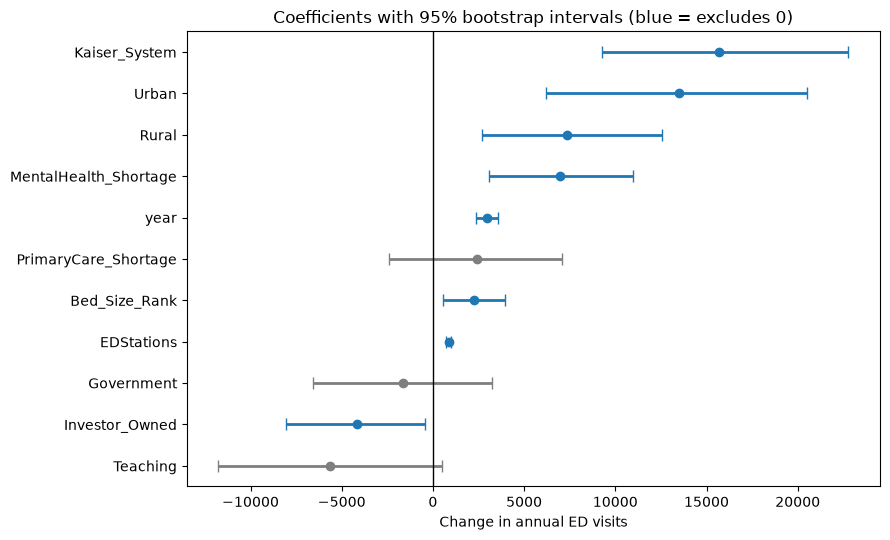

In [31]:
coef_table = pd.DataFrame({
    "Coefficient (all data)": mlr_model.coef_,
    "Bootstrap SE": boot_coefs.std().to_numpy(),
    "95% low": boot_coefs.quantile(0.025).to_numpy(),
    "95% high": boot_coefs.quantile(0.975).to_numpy(),
}, index=MLR_FEATURES)
coef_table["Interval excludes 0"] = (coef_table["95% low"] > 0) | (coef_table["95% high"] < 0)
display(coef_table.round(0).astype({"Interval excludes 0": bool}))

order = coef_table["Coefficient (all data)"].sort_values().index
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ["tab:blue" if coef_table.loc[f, "Interval excludes 0"] else "tab:gray" for f in order]
for pos, (feature, color) in enumerate(zip(order, colors)):
    est, low, high = coef_table.loc[feature, ["Coefficient (all data)", "95% low", "95% high"]]
    ax.errorbar(est, pos, xerr=[[est - low], [high - est]], fmt="o", color=color,
                ecolor=color, elinewidth=2, capsize=4)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(range(len(order)), order)
ax.set(xlabel="Change in annual ED visits", title="Coefficients with 95% bootstrap intervals (blue = excludes 0)")
plt.tight_layout()
plt.show()

Eight of the eleven coefficients have 95% bootstrap intervals that exclude zero, so their direction is dependable. Stations (718 to 1,009 visits per station, the most precise estimate), bed size, year (2,346 to 3,549 per year), urban and rural setting, mental health shortage area (3,087 to 10,953), and Kaiser membership (9,251 to 22,783) all have reliably positive effects. Investor ownership has a reliably negative one (−8,038 to −413) compared with nonprofits.

The intervals for teaching (−11,769 to 515), government ownership (−6,564 to 3,217), and primary care shortage area (−2,395 to 7,103) all cross zero, so the data cannot establish the direction of those effects. This refines our reading of Report #2, where we treated the teaching coefficient as meaningful; the bootstrap shows that it is not reliable.

## 6. Comparing Models: Adjusted R² and the One-Standard-Error Rule

Task: compare models using the one-standard-error or adjusted-R² methods, and report.

We compare a sequence of nested multiple regression models for total ED visits. Each model adds one group of attributes to the previous one, from stations alone up to our 11-attribute model, plus one larger model with location. We apply both methods:

- Adjusted R²: R² penalized for the number of attributes, computed on the full data. A new attribute raises adjusted R² only if it improves the fit more than chance would. Choose the model with the highest adjusted R².
- One-standard-error rule: estimate each model's test error with hospital-grouped 10-fold CV, together with the standard error of that estimate (fold SD ÷ √10). Find the model with the lowest CV error, then choose the simplest model whose error is within one standard error of that minimum. The rule favors simplicity when the extra attributes do not improve accuracy by more than the uncertainty in the estimate.

In [32]:
ed["LAT_STD"], ed["LON_STD"] = ed["LAT_STD"].astype(float), ed["LON_STD"].astype(float)
nested = [
    ("Stations", ["EDStations"]),
    ("+ Bed size", ["EDStations", "Bed_Size_Rank"]),
    ("+ Year", ["EDStations", "Bed_Size_Rank", "year"]),
    ("+ Urban/Rural", ["EDStations", "Bed_Size_Rank", "year", "Urban", "Rural"]),
    ("+ Ownership", ["EDStations", "Bed_Size_Rank", "year", "Urban", "Rural", "Government", "Investor_Owned"]),
    ("+ Teaching", ["EDStations", "Bed_Size_Rank", "year", "Urban", "Rural", "Government", "Investor_Owned",
                    "Teaching"]),
    ("+ Shortage areas", ["EDStations", "Bed_Size_Rank", "year", "Urban", "Rural", "Government", "Investor_Owned",
                          "Teaching", "PrimaryCare_Shortage", "MentalHealth_Shortage"]),
    ("+ Kaiser (Part 2 model)", MLR_FEATURES),
    ("+ Latitude/longitude", MLR_FEATURES + ["LAT_STD", "LON_STD"]),
]
n = len(y_mlr)
compare_rows = []
for name, cols in nested:
    fit_all = LinearRegression().fit(ed[cols], y_mlr)
    r2_all = r2_score(y_mlr, fit_all.predict(ed[cols]))
    fold_rmse = -cross_val_score(LinearRegression(), ed[cols], y_mlr, cv=cv10, scoring="neg_root_mean_squared_error")
    compare_rows.append({"Model": name, "Attributes": len(cols),
                         "R2 (all data)": r2_all,
                         "Adjusted R2": 1 - (1 - r2_all) * (n - 1) / (n - len(cols) - 1),
                         "CV RMSE (mean)": fold_rmse.mean(),
                         "CV RMSE (SE)": fold_rmse.std(ddof=1) / np.sqrt(len(fold_rmse))})
model_compare = pd.DataFrame(compare_rows).set_index("Model")

best = model_compare["CV RMSE (mean)"].idxmin()
threshold = model_compare.loc[best, "CV RMSE (mean)"] + model_compare.loc[best, "CV RMSE (SE)"]
one_se_choice = model_compare[model_compare["CV RMSE (mean)"] <= threshold].index[0]
adj_choice = model_compare["Adjusted R2"].idxmax()

display(model_compare.style.format({"R2 (all data)": "{:.3f}", "Adjusted R2": "{:.4f}",
                                    "CV RMSE (mean)": "{:,.0f}", "CV RMSE (SE)": "{:,.0f}"}))
print(f"Lowest CV error: {best} (RMSE {model_compare.loc[best, 'CV RMSE (mean)']:,.0f})")
print(f"One-SE threshold: {threshold:,.0f} visits")
print(f"One-standard-error rule chooses: {one_se_choice}")
print(f"Highest adjusted R2 chooses:     {adj_choice}")

,Attributes,R2 (all data),Adjusted R2,CV RMSE (mean),CV RMSE (SE)
Model,,,,,
Stations,1,0.687,0.6863,"15,139",336
+ Bed size,2,0.692,0.6908,"15,071",351
+ Year,3,0.699,0.6981,"14,888",358
+ Urban/Rural,5,0.704,0.7018,"14,808",335
+ Ownership,7,0.714,0.7110,"14,630",314
+ Teaching,8,0.717,0.7140,"14,587",305
+ Shortage areas,10,0.727,0.7231,"14,495",254
+ Kaiser (Part 2 model),11,0.755,0.7517,"13,788",327
+ Latitude/longitude,13,0.759,0.7548,"13,819",350


Lowest CV error: + Kaiser (Part 2 model) (RMSE 13,788)
One-SE threshold: 14,115 visits
One-standard-error rule chooses: + Kaiser (Part 2 model)
Highest adjusted R2 chooses:     + Latitude/longitude


Adjusted R² rises with each added group of attributes, from 0.686 for stations alone to 0.752 for the Part 2 model. The largest single gain comes from the Kaiser flag (0.723 to 0.752). Adding latitude and longitude raises it another 0.003, so adjusted R² favors the 13-attribute model.

The cross-validated error tells a slightly different story. It falls from 15,139 to 13,788 visits as attributes are added and reaches its lowest point at the Part 2 model; adding latitude and longitude pushes it back up to 13,819. Under the one-standard-error rule, the minimum error of 13,788 plus its standard error of 327 sets a threshold of 14,115. The next simpler model, without the Kaiser flag, has an error of 14,495, which is above that threshold, so the rule selects the 11-attribute Part 2 model.

The two methods disagree only about latitude and longitude. Adjusted R² is computed on the same data used to fit the model, so a small in-sample gain can survive its penalty. Cross-validation tests on hospitals the model has not seen, and there the extra attributes do not help. We therefore keep the 11-attribute model, which has the lowest cross-validated error, is selected by the one-standard-error rule, and is the simpler of the two.

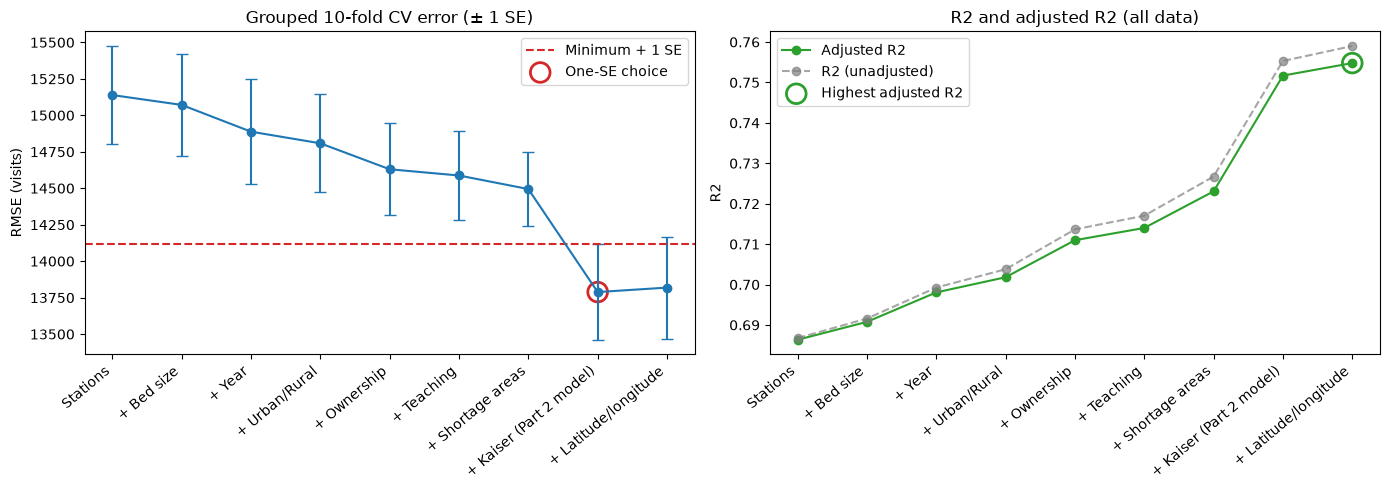

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(model_compare))
labels = model_compare.index

axes[0].errorbar(x, model_compare["CV RMSE (mean)"], yerr=model_compare["CV RMSE (SE)"],
                 fmt="o-", capsize=4, color="tab:blue")
axes[0].axhline(threshold, color="tab:red", linestyle="--", label="Minimum + 1 SE")
axes[0].scatter([list(labels).index(one_se_choice)], [model_compare.loc[one_se_choice, "CV RMSE (mean)"]],
                s=200, facecolors="none", edgecolors="tab:red", linewidths=2, label="One-SE choice")
axes[0].set(title="Grouped 10-fold CV error (± 1 SE)", ylabel="RMSE (visits)")
axes[0].legend()

axes[1].plot(x, model_compare["Adjusted R2"], "o-", color="tab:green", label="Adjusted R2")
axes[1].plot(x, model_compare["R2 (all data)"], "o--", color="gray", alpha=0.7, label="R2 (unadjusted)")
axes[1].scatter([list(labels).index(adj_choice)], [model_compare.loc[adj_choice, "Adjusted R2"]],
                s=200, facecolors="none", edgecolors="tab:green", linewidths=2, label="Highest adjusted R2")
axes[1].set(title="R2 and adjusted R2 (all data)", ylabel="R2")
axes[1].legend()

for ax in axes:
    ax.set_xticks(x, labels, rotation=40, ha="right")
plt.tight_layout()
plt.show()

The left plot illustrates the one-standard-error rule. Only the Part 2 model and the latitude/longitude model fall below the red threshold, and of those two the Part 2 model is simpler. The right plot shows R² and adjusted R² rising together. The gap between them stays small because 756 rows is large relative to at most 13 attributes, so the adjustment is mild. In both plots, the Kaiser flag produces the biggest improvement.

## Conclusion

In this report we evaluated our models with loss functions, cross-validation, the bootstrap, and formal model comparison.

For the regression models, the two-attribute model of stations from visits has an RMSE of about 12 stations (R² = 0.69). The 11-attribute model of annual visits has an out-of-fold RMSE of 13,815 visits and an MAE of 9,932 (R² = 0.74), and it beats the stations-only model on every loss function. For classification, the six single-attribute logistic models have log losses between 0.25 and 0.66, but compared with a no-skill baseline only stations and bed size carry useful information, and none classifies well at a 0.5 cutoff. Combining five attributes changed that. The combined model identifies urban hospitals with 90.2% accuracy on hospitals it never saw, cuts the no-skill log loss roughly in half, and reaches an AUC of 0.92.

Cross-validation showed that 10-fold and LOOCV give nearly the same answer, while a single train-test split can land almost anywhere in a wide range; the multiple model's RMSE varied from 11,538 to 15,847 visits depending only on the random seed. The bootstrap estimated the multiple model's error at 14,105 ± 1,077 visits (RMSE) and 10,214 ± 726 visits (MAE), with R² holding between about 0.63 and 0.79, and it showed that eight of the eleven coefficients are reliably different from zero. Finally, the one-standard-error rule confirmed the 11-attribute model, while adjusted R² slightly favored adding location, an addition cross-validation showed does not help with new hospitals.

We took four lessons from this work. Models should be judged on data they have not seen, and with this dataset that means keeping each hospital's years together. Reproducibility is part of getting the answer right; until we fixed the fold assignment ourselves, the same code produced different scores in different versions of scikit-learn. Every loss value needs a reference point, since a logistic model can post 90% accuracy and still do no better than guessing the majority class. And an estimate is only as useful as our sense of its uncertainty: the bootstrap separated the dependable findings (the Kaiser, setting, and size effects) from the uncertain ones (the teaching effect).

For our project goal of directing ED resources where demand is highest, the 11-attribute model predicts a hospital's annual visit volume to within about 14,000 visits with a known and stable margin of error. The success of the combined logistic model also points the way forward: in the next report we will apply supervised and unsupervised learning methods that use several attributes at once.